# Advanced Data Preparation with Pipelines -  Geochemical Survey Canada

This data problem was given as assessed coursework in 2022. It presents a great opportunity to practice your skills with pipelines and data preparation, as well as EDA and general thinking. Your client is the **Canadian Government**. As part of their ***open government*** digital initiative, they have collected a lot of information about river sediments and the general river conditions in the Province of British Columbia.

The Canadian Government has many data scientists, so they are <strong style="color:brown">not interested in you doing any machine learning modelling</strong>. Rather, they need you to prepare the data for them, so their data scientists can do the modelling with already prepared data.

### What Regional Canada wants you to do is the following:
<p>🍁 Load the data by running the cell below: <strong style="color:blue">this will be all the training data that you have</strong>. Since you are not doing any machine learning modelling, consider all of the features to be your <code>X</code> features (there is no <code>y</code> in this exercise).</p>
<p>🍁 In order <strong>to be fair</strong> when assessing your work against others, the Canadian Government informs you that for any algorithm where a <strong style="color:blue">random state</strong> is needed you should use <code>random_state=42</code>. Note that this does not necessarily imply that you need an operation that requires a random_state: but if you do, use 42 so you can be fairly assessed against other biders!</p> 
<p>🍁 The client also informs you that they intend to use your <code>X_train</code> and <code>X_test</code> sets (see instructions below) for their own machine learning modeling in order to <strong style="color:blue">predict properties outside of British Columbia</strong>, so take this into consideration when you prepare the data.</p>
<p>🍁 Your client is <strong>NOT interested in advanced feature engineering</strong>: so, for instance, don't bother with FeatureCross or coming up with new features as they don't want this at this stage and won't reward you for it.</p>

#### Objective I
<p>🍁 Your first objective is to  <strong style="color:blue">prepare</strong> a <code>X_train</code> (80% of the dataset), and a <code>X_test</code> (20% of the dataset). You need to prepare the two sets following the <strong style="color:blue">best practices in data science</strong>, and you need to name these objects in your notebook <code>X_train</code> and <code>X_test</code>.</p> 
<p>🍁 Your client want you to create a pipeline to <strong style="color:teal">process the numerical features in your dataset</strong>. This data preparation pipeline should be called <code>num_pipe</code>. You should  <strong>remove unnecessary numerical features</strong>, but you need to make a good case as to <strong style="color:blue">why</strong> you remove the features, i.e. it needs to be motivated by sound data science principles for future ML modelling. It is advisable to use a <strong>markdown</strong> cell to explain to your client why you would remove certain features.</p>

#### Objective II
<p>🍁 Your client also wants you to <strong style="color:teal">prepare the categorical features</strong>. Call your categorical pipeline <code>cat_pipe</code></p>
<p>🍁 Then, the client wants both your <code>num_pipe</code> and your <code>cat_pipe</code> to be <strong style="color:teal">wrapped in a single, final data pipeline able to process raw data</strong>: they want this pipeline to be saved in your notebook as <code>final_preprocessor</code>. The Government has more data and they intend to prepare it using your pipeline for evaluation.</p>
<p>🍁 Make sure to use your <code>final_preprocessor</code> to transform your <code>X_train</code> and <code>X_test</code> in your notebook: these will be assessed too Keep the raw frames and save the results as <code>X_train_processed</code> and <code>X_test_processed</code>.</p>


#### Your client will judge your work on the following criteria:
<p>❄️ How clean and easy to read your code is, and how well structure your notebook is: this includes using markdown cells to explain your decisions if needed (don't justify all basic decisions though: the code needs to speak for itself)</p>
<p>❄️ The overall performance of your pipeline at preparing similar data from <strong>an unseen dataset</strong>.</p>
<p>❄️ Whether or not you have demonstrated through code that your solution follows the best practices of data science, and is as complete as possible.</p>
<br>

###  🦫 Good luck!

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
import numpy as np
import pandas as pd



In [2]:
# Run this cell first in order to be able to see changes in your "custom_transformers.py" file without needing to restart your kernel
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd

river_data = pd.read_csv('../../Excercise_data/L08/river_sediments.csv')
river_data

,MASTERID,UPDATE_REP1,UPDATE_REP2,UPDATE_REP3,NAME,TYPE2,YEAR,LAT,LONG,CATCH_AREA,...,W_INA_PPM,Yb_INA_PPM,Zn_INA_PPM,Zr_INA_PPM,WT_INA_g,pH,Uw_LIF_PPB,Fw_ISE_PPB,SO4_TRB_PPM,Cnd_uS/cm
0,ID093B063330,NaN,NaN,NaN,CARIBOO,LAKE,2006,52.101180,-123.053040,NaN,...,-1.0,2.0,NaN,NaN,12.76,8.71,NaN,110.0,NaN,215.0
1,ID104G873620,NaN,GBC 2011-02,GBC 2012-06,TELEGRAPH,STRM,1987,57.824970,-131.495970,NaN,...,-1.0,2.0,110.0,240.0,19.46,7.60,-0.05,30.0,NaN,NaN
2,ID094E961325,GF 2005-22,GBC 2011-02,NaN,TOODOGGONE RIVER,STRM,1996,57.943520,-126.873210,NaN,...,-1.0,1.0,NaN,NaN,30.73,7.10,0.30,-20.0,-1.0,NaN
3,ID103I787491,RGS 42,GBC 2008-11,NaN,TERRACE,STRM,1978,54.063940,-129.188970,NaN,...,-2.0,3.0,NaN,390.0,45.91,6.00,-0.05,-20.0,NaN,NaN
4,ID104G111145,NaN,NaN,NaN,QUEST NW,STRM,2011,57.776150,-131.904200,NaN,...,6.0,3.0,150.0,-200.0,33.06,7.60,NaN,30.0,NaN,101.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17108,ID104G111122,NaN,NaN,NaN,QUEST NW,STRM,2011,57.601930,-131.549070,NaN,...,-1.0,3.0,130.0,-200.0,39.78,8.20,NaN,33.0,NaN,121.0
17109,ID092P065429,NaN,NaN,NaN,CARIBOO,LAKE,2006,51.356360,-121.027520,NaN,...,-1.0,-2.0,NaN,NaN,8.08,8.61,NaN,340.0,NaN,497.0
17110,ID093O071419,NaN,NaN,NaN,PINE PASS,STRM,2007,55.382320,-122.237530,NaN,...,-1.0,-2.0,NaN,NaN,9.83,NaN,NaN,240.0,NaN,NaN
17111,ID082N051296,NaN,NaN,NaN,GOLDEN,STRM,2005,51.152260,-116.350450,NaN,...,-2.0,1.4,-50.0,NaN,8.95,8.24,NaN,30.0,NaN,197.0


## Step 1: remove duplicates

In [4]:
river_data.duplicated().sum()

1556

In [5]:
river_data = river_data.drop_duplicates()

In [6]:
river_data.duplicated().sum()

0

## Step 2: Geographic train-test-split

We are asked to evaluate transfer to new regions, and we are looking at geographical data. Let's check if we have latitude and longitude. If yes, in order to do a proper train-test-split, we need to plot the data to inspect its geographic distribution:

In [7]:
import numpy as np 

river_data.select_dtypes(include = np.number)

,YEAR,LAT,LONG,CATCH_AREA,WDTH,DPTH,MS_HGTH,MS_THICK,LK_AREA,LK_PERI,...,W_INA_PPM,Yb_INA_PPM,Zn_INA_PPM,Zr_INA_PPM,WT_INA_g,pH,Uw_LIF_PPB,Fw_ISE_PPB,SO4_TRB_PPM,Cnd_uS/cm
0,2006,52.101180,-123.053040,NaN,NaN,NaN,NaN,NaN,0.04,0.85,...,-1.0,2.0,NaN,NaN,12.76,8.71,NaN,110.0,NaN,215.0
1,1987,57.824970,-131.495970,NaN,3.5,15.0,NaN,NaN,NaN,NaN,...,-1.0,2.0,110.0,240.0,19.46,7.60,-0.05,30.0,NaN,NaN
2,1996,57.943520,-126.873210,NaN,2.0,40.0,NaN,NaN,NaN,NaN,...,-1.0,1.0,NaN,NaN,30.73,7.10,0.30,-20.0,-1.0,NaN
3,1978,54.063940,-129.188970,NaN,5.0,30.0,NaN,NaN,NaN,NaN,...,-2.0,3.0,NaN,390.0,45.91,6.00,-0.05,-20.0,NaN,NaN
4,2011,57.776150,-131.904200,NaN,3.0,50.0,NaN,NaN,NaN,NaN,...,6.0,3.0,150.0,-200.0,33.06,7.60,NaN,30.0,NaN,101.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17107,1990,50.355096,-115.235247,NaN,2.0,95.0,NaN,NaN,NaN,NaN,...,-2.0,-2.0,NaN,-200.0,10.00,8.20,0.26,38.0,NaN,NaN
17108,2011,57.601930,-131.549070,NaN,2.0,50.0,NaN,NaN,NaN,NaN,...,-1.0,3.0,130.0,-200.0,39.78,8.20,NaN,33.0,NaN,121.0
17109,2006,51.356360,-121.027520,NaN,NaN,NaN,NaN,NaN,0.03,0.93,...,-1.0,-2.0,NaN,NaN,8.08,8.61,NaN,340.0,NaN,497.0
17111,2005,51.152260,-116.350450,NaN,4.0,20.0,NaN,NaN,NaN,NaN,...,-2.0,1.4,-50.0,NaN,8.95,8.24,NaN,30.0,NaN,197.0


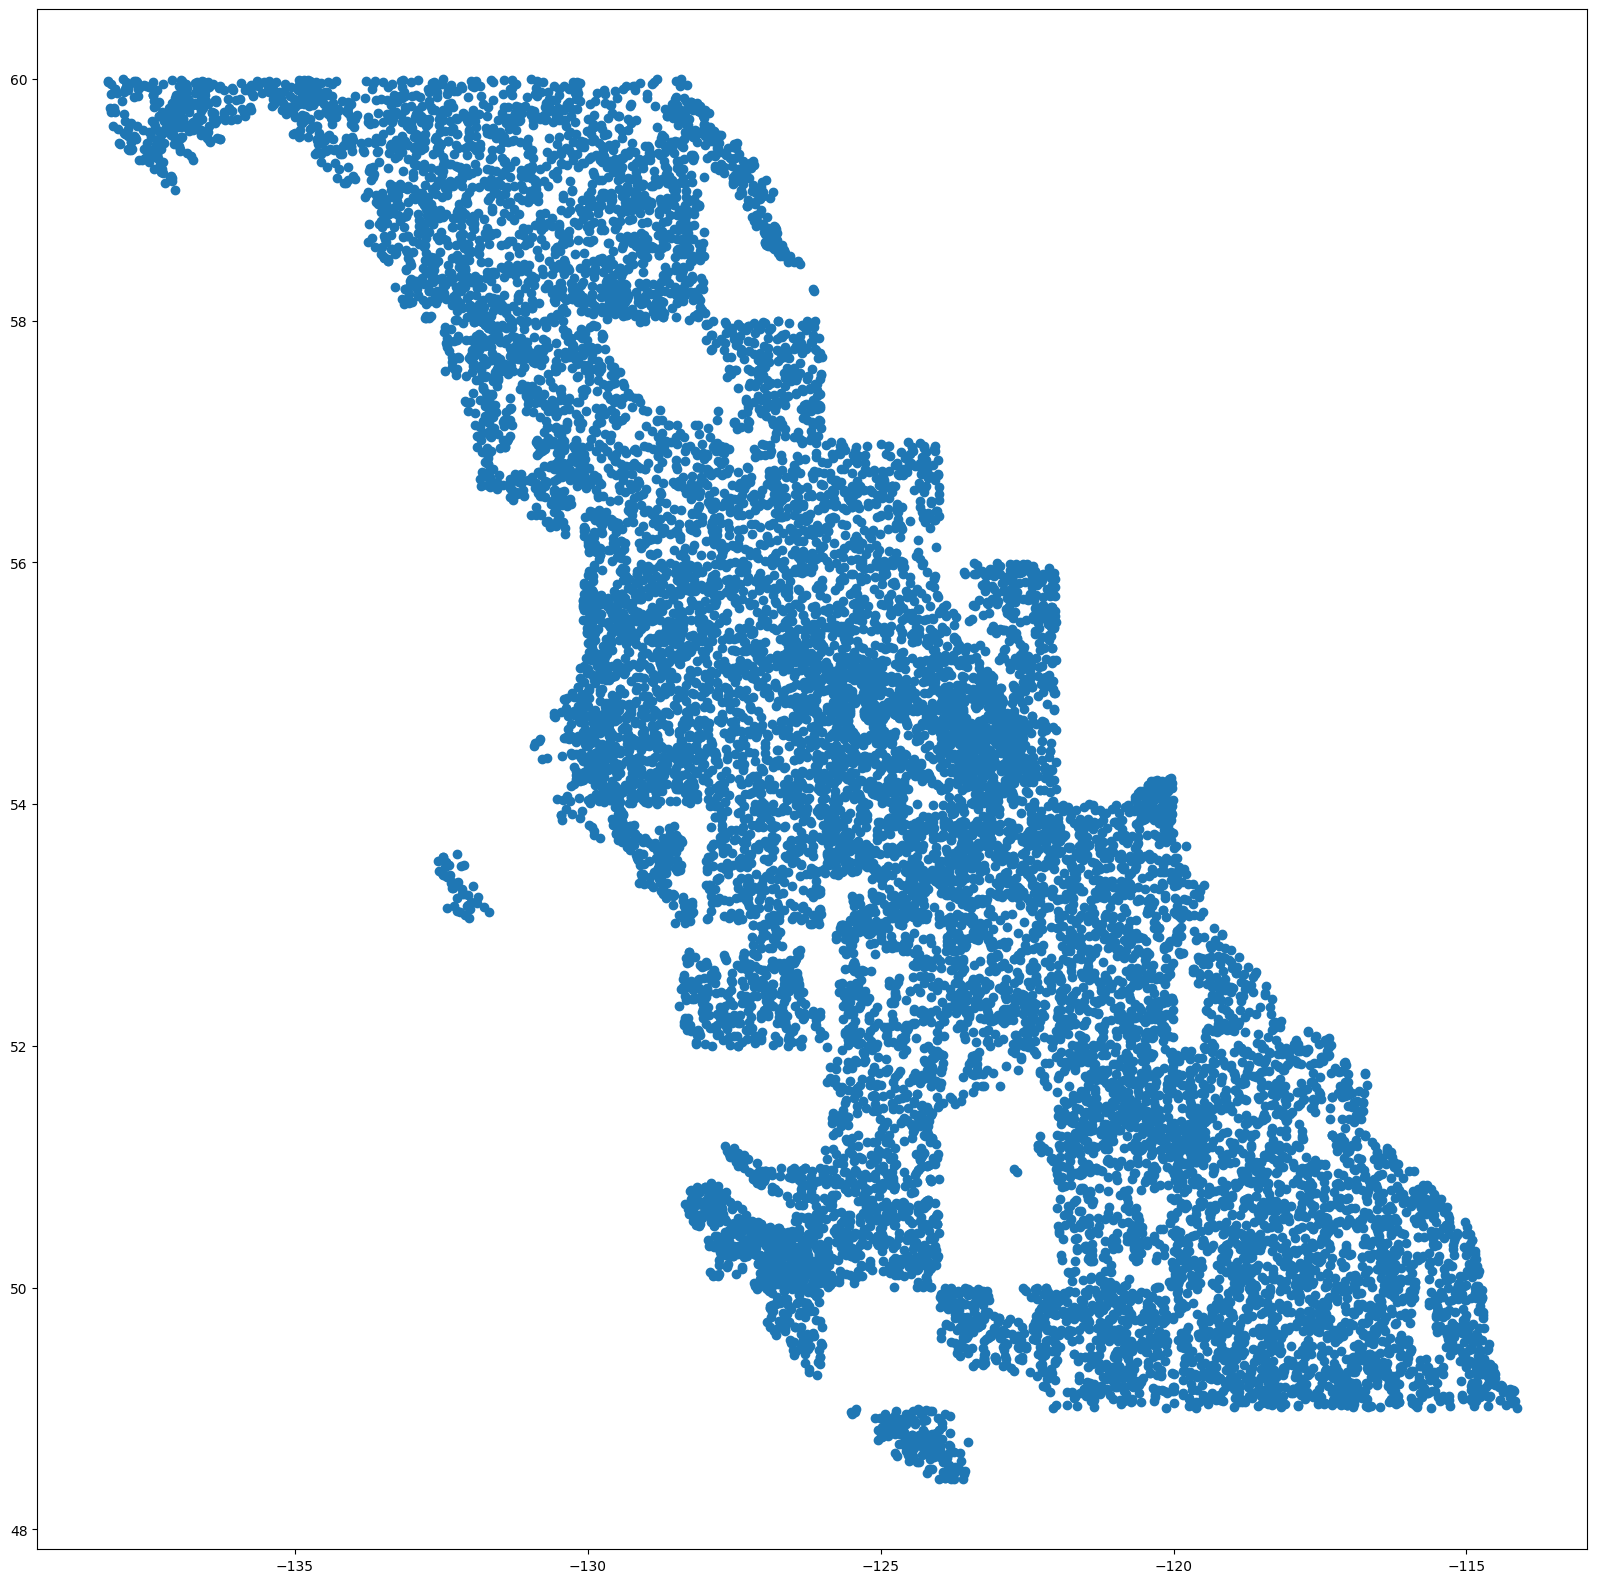

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,1, figsize=(20,20))

ax.scatter(river_data.LONG, river_data.LAT);

### Strategy

Based on the above, it is pretty clear that we need to split the data geographically. My strategy will be to sort the data by latitude first, and then longitude, and take the first 20% to the North as my test set, and the rest as my train set. Other strategies are of course possible.

In [9]:
test_frac = int(river_data.shape[0]*.2)+1
test_frac

3112

In [10]:
sorted_data = river_data.sort_values(by=['LAT', 'LONG'], ascending=False)
sorted_data

,MASTERID,UPDATE_REP1,UPDATE_REP2,UPDATE_REP3,NAME,TYPE2,YEAR,LAT,LONG,CATCH_AREA,...,W_INA_PPM,Yb_INA_PPM,Zn_INA_PPM,Zr_INA_PPM,WT_INA_g,pH,Uw_LIF_PPB,Fw_ISE_PPB,SO4_TRB_PPM,Cnd_uS/cm
13483,ID104O785913,RGS 52,GBC 2011-02,NaN,JENNINGS RIVER,STRM,1978,59.998270,-130.967650,NaN,...,-2.0,3.0,NaN,360.0,21.87,8.0,0.30,94.0,NaN,NaN
8267,ID114P921415,NaN,NaN,NaN,TATSHENSHINI,STRM,1992,59.998000,-137.926000,NaN,...,-1.0,1.9,NaN,NaN,13.29,8.0,0.06,-20.0,4.3,NaN
12047,ID104N777099,RGS 51,GBC 2017-04,NaN,ATLIN,STRM,1977,59.997652,-132.466388,NaN,...,-2.0,-2.0,NaN,-200.0,7.83,7.3,0.50,52.0,NaN,NaN
13006,ID104P964204,GBC 2011-02,NaN,NaN,KECHIKA,LAKE,1996,59.997590,-128.410950,NaN,...,-1.0,1.3,117.0,NaN,20.27,8.2,0.25,66.0,5.0,375.0
12964,ID104P781044,RGS 53,GBC 2011-02,NaN,MCDAME,STRM,1978,59.996950,-128.822850,NaN,...,-2.0,-2.0,NaN,-200.0,25.60,8.3,0.32,92.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10967,ID092B891104,GBC 2011-04,NaN,NaN,VICTORIA,MOSS,1989,48.423200,-123.901490,NaN,...,NaN,NaN,NaN,NaN,NaN,6.0,-0.05,-20.0,NaN,NaN
12665,ID092B891152,GBC 2011-04,NaN,NaN,VICTORIA,MOSS,1989,48.417930,-123.588760,NaN,...,NaN,NaN,NaN,NaN,NaN,6.6,-0.05,-20.0,NaN,NaN
14638,ID092B891148,GBC 2011-04,NaN,NaN,VICTORIA,MOSS,1989,48.417480,-123.801190,NaN,...,NaN,NaN,NaN,NaN,NaN,6.2,-0.05,-20.0,NaN,NaN
1501,ID092B891011,GBC 2011-04,NaN,NaN,VICTORIA,MOSS,1989,48.414470,-123.751730,NaN,...,NaN,NaN,NaN,NaN,NaN,6.6,-0.05,22.0,NaN,NaN


In [11]:
X_test = sorted_data.iloc[:test_frac].copy()
X_train = sorted_data.iloc[test_frac:].copy()

In [12]:
X_test.shape[0]/(X_test.shape[0]+X_train.shape[0])

0.20003856784727134

### Important: visual check of train/test split

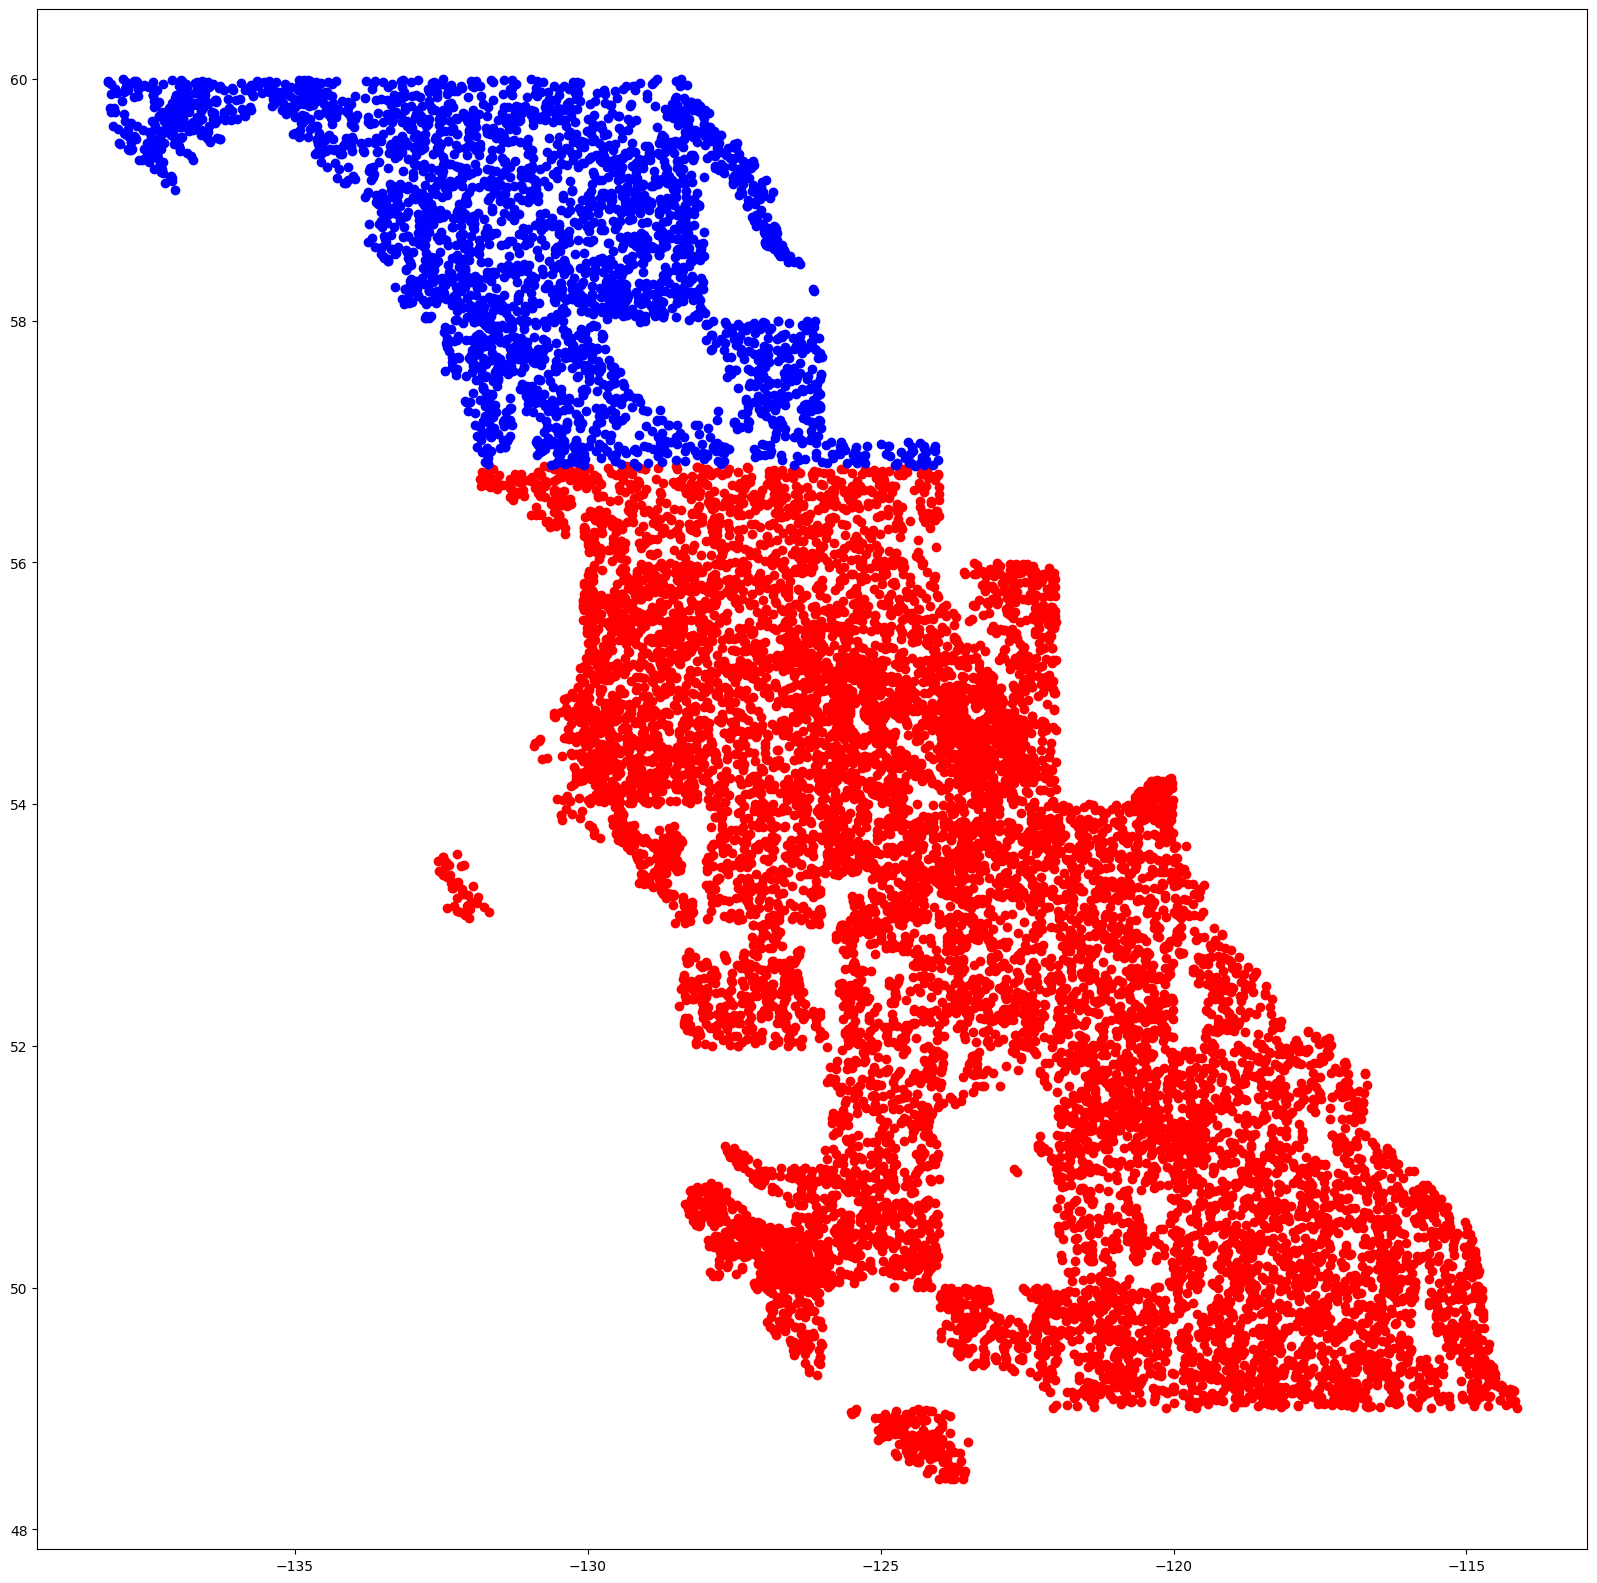

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1,1, figsize=(20,20))

ax.scatter(X_train.LONG, X_train.LAT, c='r', label='X_train');
ax.scatter(X_test.LONG, X_test.LAT, c='b', label='X_test');

## Step 3: Identify and separate numerical and categorical columns right at the beginning.


In [14]:
numerical_cols = X_train.select_dtypes(include=np.number).columns
categorical_cols = X_train.select_dtypes(include='object').columns

In [15]:
numerical_cols.shape, categorical_cols.shape

((152,), (31,))

## Numerical data processing
Negative longitude is valid and must be preserved. Negative reported elemental concentrations may encode detection limits or missingness; their meaning is not documented in the CSV.

For this exercise only, treat negative values in columns labelled as concentration measurements as missing. This is a provisional demonstration policy, not a validated treatment of censored measurements. Obtain the data dictionary before scientific use.

Drop numerical columns with over 30% missing values according to this policy, then impute using the training data.

In [16]:
# Provisional concentration policy before measuring missingness.
candidate_numeric = X_train[numerical_cols].copy()
concentration_cols = [
    col for col in numerical_cols
    if col.endswith(('_PPB', '_PPM', '_PCT'))
]
candidate_numeric[concentration_cols] = candidate_numeric[concentration_cols].mask(
    candidate_numeric[concentration_cols] < 0
)
candidate_numeric = candidate_numeric.replace([np.inf, -np.inf], np.nan)
missing_num_cols = candidate_numeric.isna().mean()
num_cols_to_drop = missing_num_cols[missing_num_cols > 0.3].index

In [17]:
num_cols_to_drop

Index(['CATCH_AREA', 'MS_HGTH', 'MS_THICK', 'LK_AREA', 'LK_PERI', 'LK_DPTH',
       'Au_FA_PPB', 'Au_FA_wt_gr', 'Au1_FA_PPB', 'Au1_FA_wt_gr', 'Ag_FA_PPM',
       'Pd_FA_PPB', 'Pt_FA_PPB', 'PGE_FA_wt_gr', 'Ag_AAS_PPM', 'As_AAS_PPM',
       'Ba_AAS_PPM', 'Bi_AAS_PPM', 'Cd_AAS_PPM', 'Co_AAS_PPM', 'Cr_AAS_PPM',
       'Fe_AAS_PCT', 'Hg_AAS_PPB', 'Mn_AAS_PPM', 'Mo_AAS_PPM', 'Ni_AAS_PPM',
       'Pb_AAS_PPM', 'Sb_AAS_PPM', 'Se_AAS_PPM', 'Sn_AAS_PPM', 'V_AAS_PPM',
       'U_NAD_PPM', 'W_CLR_PPM', 'F_ISE_PPM', 'LOI_GRV_PCT', 'Au_ICP_PPB',
       'B_ICP_PPM', 'Te_ICP_PPM', 'W_ICP_PPM', 'Be_ICP_PPM', 'Ce_ICP_PPM',
       'Pr_ICP_PPM', 'Nd_ICP_PPM', 'Sm_ICP_PPM', 'Eu_ICP_PPM', 'Gd_ICP_PPM',
       'Tb_ICP_PPM', 'Dy_ICP_PPM', 'Ho_ICP_PPM', 'Er_ICP_PPM', 'Tm_ICP_PPM',
       'Yb_ICP_PPM', 'Lu_ICP_PPM', 'Cs_ICP_PPM', 'Ge_ICP_PPM', 'Hf_ICP_PPM',
       'In_ICP_PPM', 'Li_ICP_PPM', 'Nb_ICP_PPM', 'Re_ICP_PPB', 'Rb_ICP_PPM',
       'Sn_ICP_PPM', 'Ta_ICP_PPM', 'Y_ICP_PPM', 'Zr_ICP_PPM', 'Pt_ICP_PPB',
    

In [18]:
numerical_cols = numerical_cols.difference(num_cols_to_drop)

In [19]:
numerical_cols.shape

(57,)

### Checking the statistics:


In [20]:
X_train[numerical_cols].describe()


,Ag_ICP_PPB,Al_ICP_PCT,As_ICP_PPM,As_INA_PPM,Ba_ICP_PPM,Ba_INA_PPM,Bi_ICP_PPM,Br_INA_PPM,Ca_ICP_PCT,Cd_ICP_PPM,...,Tl_ICP_PPM,U_ICP_PPM,U_INA_PPM,V_ICP_PPM,WDTH,WT_INA_g,YEAR,Zn_AAS_PPM,Zn_ICP_PPM,pH
count,10921.000000,10944.000000,10944.000000,10093.000000,10944.000000,10093.000000,10944.000000,10093.000000,10938.000000,10944.000000,...,10944.000000,10944.000000,10093.000000,10944.000000,10284.000000,9791.000000,12445.000000,8748.000000,10944.000000,11906.000000
mean,150.570277,1.299206,7.753826,9.176043,124.013048,658.853958,0.173519,17.542634,1.529457,0.402943,...,0.093633,2.699167,5.327752,52.029660,3.010142,21.092968,1990.305745,76.457590,76.190378,7.354816
std,731.577832,0.729903,27.031618,29.346082,135.233627,456.614756,1.419259,26.580462,3.271611,1.297767,...,0.135825,9.751741,12.033237,41.968737,3.071528,11.918623,11.301178,148.417953,140.401129,0.801662
min,-2.000000,-0.010000,-0.100000,-2.700000,0.500000,-170.000000,-0.020000,-2.300000,0.010000,-0.010000,...,-0.020000,-0.100000,-0.600000,-2.000000,0.000000,0.810000,1976.000000,4.000000,0.100000,2.900000
25%,38.000000,0.780000,1.300000,2.000000,52.900000,370.000000,0.050000,2.800000,0.420000,0.080000,...,0.040000,0.500000,1.800000,25.000000,1.000000,10.500000,1980.000000,39.000000,40.600000,6.900000
50%,75.000000,1.190000,3.600000,4.500000,95.150000,600.000000,0.090000,6.900000,0.650000,0.180000,...,0.070000,1.000000,2.800000,44.000000,2.000000,19.070000,1988.000000,59.000000,61.000000,7.400000
75%,161.000000,1.710000,7.600000,9.300000,156.900000,880.000000,0.160000,21.000000,1.070000,0.420000,...,0.120000,2.200000,5.100000,65.000000,4.000000,30.000000,2002.000000,88.000000,90.500000,7.900000
max,57635.000000,7.560000,1561.500000,1450.000000,6379.500000,10780.000000,125.220000,526.000000,36.830000,83.390000,...,5.190000,501.700000,502.000000,545.000000,55.000000,68.670000,2019.000000,9400.000000,9632.400000,10.810000


**Concentration cleaning:** apply the stated provisional policy only to concentration columns. Keep signed coordinates and other valid negative measurements.

In [21]:
def clean_concentrations(X):
    X = np.asarray(X, dtype=float).copy()
    X[(X < 0) | ~np.isfinite(X)] = np.nan
    return X

## Collinearity check
Inspect highly correlated concentration measurements. Correlation alone is not a scientific reason to discard a measurement. The example below drops later concentration columns above a threshold; this rule is order-dependent and preserves coordinates.

In [22]:
corr_matrix = candidate_numeric[numerical_cols].corr().abs()
corr_matrix

,Ag_ICP_PPB,Al_ICP_PCT,As_ICP_PPM,As_INA_PPM,Ba_ICP_PPM,Ba_INA_PPM,Bi_ICP_PPM,Br_INA_PPM,Ca_ICP_PCT,Cd_ICP_PPM,...,Tl_ICP_PPM,U_ICP_PPM,U_INA_PPM,V_ICP_PPM,WDTH,WT_INA_g,YEAR,Zn_AAS_PPM,Zn_ICP_PPM,pH
Ag_ICP_PPB,1.000000,0.053634,0.444406,0.479744,0.041907,0.028724,0.073505,0.021665,0.017529,0.540413,...,0.048422,0.015481,0.006169,0.004388,0.024177,0.037734,0.001044,0.686666,0.622711,0.019043
Al_ICP_PCT,0.053634,1.000000,0.075161,0.079800,0.106489,0.041482,0.003642,0.167372,0.238076,0.022397,...,0.061463,0.017219,0.028366,0.499953,0.039739,0.116116,0.043584,0.100823,0.116573,0.155674
As_ICP_PPM,0.444406,0.075161,1.000000,0.987748,0.081535,0.066152,0.501349,0.013634,0.006269,0.609216,...,0.063215,0.014510,0.018948,0.017913,0.011042,0.017321,0.031785,0.725125,0.684878,0.040127
As_INA_PPM,0.479744,0.079800,0.987748,1.000000,0.085901,0.089813,0.513998,0.017875,0.019406,0.598628,...,0.046266,0.016909,0.019504,0.027672,0.010014,0.031931,0.051229,0.720846,0.680294,0.051860
Ba_ICP_PPM,0.041907,0.106489,0.081535,0.085901,1.000000,0.462019,0.008561,0.065860,0.003938,0.087611,...,0.153135,0.013055,0.000705,0.004766,0.148223,0.076353,0.060388,0.064605,0.078295,0.059344
Ba_INA_PPM,0.028724,0.041482,0.066152,0.089813,0.462019,1.000000,0.004789,0.361606,0.192152,0.038820,...,0.072626,0.004394,0.063093,0.030867,0.148591,0.240489,0.370036,0.038372,0.056994,0.025035
Bi_ICP_PPM,0.073505,0.003642,0.501349,0.513998,0.008561,0.004789,1.000000,0.023763,0.005378,0.533376,...,0.036508,0.058145,0.086777,0.015821,0.009419,0.004483,0.044104,0.494999,0.567326,0.007061
Br_INA_PPM,0.021665,0.167372,0.013634,0.017875,0.065860,0.361606,0.023763,1.000000,0.207398,0.016266,...,0.045156,0.030710,0.035548,0.049967,0.014820,0.300780,0.348865,0.042194,0.001281,0.153104
Ca_ICP_PCT,0.017529,0.238076,0.006269,0.019406,0.003938,0.192152,0.005378,0.207398,1.000000,0.020271,...,0.002978,0.009655,0.046815,0.151588,0.022120,0.190673,0.129801,0.014378,0.027047,0.343330
Cd_ICP_PPM,0.540413,0.022397,0.609216,0.598628,0.087611,0.038820,0.533376,0.016266,0.020271,1.000000,...,0.301137,0.011074,0.004723,0.033423,0.022343,0.077669,0.024021,0.913372,0.889379,0.059627


In [23]:
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [col for col in upper_tri.columns
                   if col in concentration_cols and (upper_tri[col] > 0.75).any()]
numerical_cols = numerical_cols.difference(high_corr_pairs)

## Scaling and transformation: Analyze the histogram of each numerical column

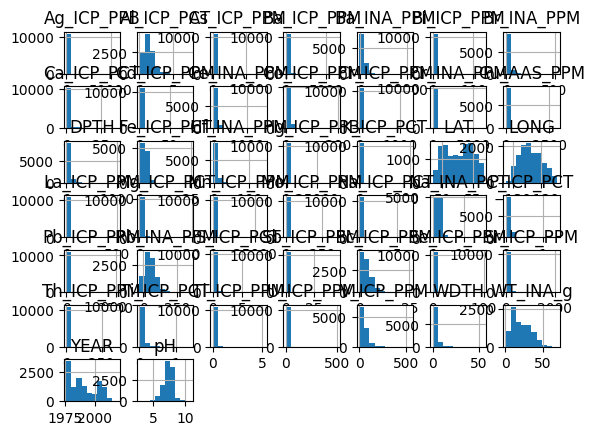

In [24]:
X_train[numerical_cols].hist();

### Scaling and transformation
Log-transform retained concentrations after cleaning and imputation. Keep coordinates and other numeric fields on a separate branch. A Pipeline applies steps in sequence; a ColumnTransformer combines branches in parallel.

In [25]:
num_cols_for_log = [col for col in numerical_cols if col in concentration_cols]
other_numeric_cols = [col for col in numerical_cols if col not in num_cols_for_log]

def log_transform(X):
    return np.log1p(X)

def clean_numeric(X):
    X = np.asarray(X, dtype=float).copy()
    X[~np.isfinite(X)] = np.nan
    return X

# Inspecting Categorical columns
Missing Value Handling: Drop columns with over 30% missing values. Replace any 'Undefined' strings in the remaining columns with NaN and impute as needed.


In [26]:
missing_cat_cols = X_train[categorical_cols].replace('Undefined', np.nan).isna().mean()
cat_cols_to_drop = missing_cat_cols[missing_cat_cols > 0.3].index
categorical_cols = categorical_cols.difference(cat_cols_to_drop)

In [27]:
# Raw frames stay unchanged. Category cleaning belongs in cat_pipe
# so it also runs on future raw data.

### Review categorical features
Inspect cardinality and domain meaning before encoding. A category need not be balanced to be informative.

In [28]:
categorical_cols

Index(['BANK', 'COMP', 'DRNP', 'FLOW', 'MASTERID', 'MAT', 'NAME', 'ORDR',
       'PHYS', 'SEDC', 'SORC', 'STRAT', 'TYPE', 'TYPE2', 'WTRC'],
      dtype='object')

In [29]:
# Display value counts for the categorical columns
X_train['WTRC'].value_counts()
#X_train['BANK'].value_counts()
#...

WTRC
Colourless      7798
Brown/Clear     1061
Clear            623
White/Cloudy     530
Brown/Cloudy      96
Other              4
Brown              1
Name: count, dtype: int64

- Drop identifiers or fields unsuitable for the intended task.
- Consider grouping rare categories when defensible.
- Keep valid categories for encoding, including imbalanced ones.

In [30]:
review_results = {col: X_train[col].value_counts().head(10) for col in categorical_cols}
review_results


{'BANK': BANK
 Alluvial            3804
 Colluvial           2448
 Till                 965
 Undefined            945
 Bare Rock            662
 Organic              614
 Glacial Till         476
 Glacial Outwash      191
 Talus/Scree           67
 Alluvial/Organic      28
 Name: count, dtype: int64,
 'COMP': COMP
 2\2\0    2042
 1\3\0    1183
 1\2\1     902
 3\1\0     865
 1\2\0     747
 2\1\0     649
 2\1\1     580
 0\3\0     494
 2\2\1     486
 0\2\2     307
 Name: count, dtype: int64,
 'DRNP': DRNP
 Dendritic             7325
 Herringbone           1026
 Poorly Defined         399
 Trellised              253
 Interrupted            196
 Rectangular             65
 Glacially Deranged      21
 Other                   12
 Trellis                  9
 Basinal                  5
 Name: count, dtype: int64,
 'FLOW': FLOW
 Moderate    3819
 Fast        3578
 Slow        1693
 Torrent      650
 Stagnant     370
 Name: count, dtype: int64,
 'MASTERID': MASTERID
 ID104B871259    1
 ID092N9110

### Proposed categorical choices
Drop `MASTERID` and `NAME` as identifiers. Drop `STRAT` provisionally because this exercise has no target or domain scheme for its detailed categories; revisit this with a geologist.

The fixed grouping choices below simplify rare categories. They are modelling choices, not proof that merged categories are scientifically equivalent. The encoder handles unknown future categories.

In [31]:
categorical_cols = categorical_cols.difference(['MASTERID', 'NAME', 'STRAT'])



In [32]:
categorical_cols

Index(['BANK', 'COMP', 'DRNP', 'FLOW', 'MAT', 'ORDR', 'PHYS', 'SEDC', 'SORC',
       'TYPE', 'TYPE2', 'WTRC'],
      dtype='object')

In [33]:
def group_rare_categories(X):
    X = pd.DataFrame(X, columns=categorical_cols).copy().replace('Undefined', np.nan)
    groups = {
        'BANK': ['Talus/Scree', 'Alluvial/Organic', 'Other'],
        'PHYS': ['Lowland', 'Swamp/Muskeg'],
        'SORC': ['Ground', 'Groundwater/Spring Run-off',
                 'Groundwater/Recent Precipitation', 'Glacial Melt water'],
        'WTRC': ['Brown', 'Other']
    }
    for col, values in groups.items():
        if col in X.columns:
            X[col] = X[col].replace(values, 'Other')
    return X

# Construct the numerical pipeline

In [34]:
concentration_pipe = Pipeline([
    ('clean', FunctionTransformer(clean_concentrations)),
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(log_transform)),
    ('scaler', StandardScaler())
])
other_numeric_pipe = Pipeline([
    ('clean', FunctionTransformer(clean_numeric)),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
num_pipe = ColumnTransformer([
    ('concentrations', concentration_pipe, num_cols_for_log),
    ('other_numeric', other_numeric_pipe, other_numeric_cols)
])

# Construct the categorical pipeline

In [35]:
cat_pipe = Pipeline([
    ('group_rare_categories', FunctionTransformer(group_rare_categories, validate=False)),  # Group rare categories
    ('imputer', SimpleImputer(strategy='most_frequent')),                                  # Impute missing values
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=True))                # One-hot encode with sparse output
])





In [36]:
# Combine numerical and categorical pipelines
final_preprocessor = ColumnTransformer([
    ('num', num_pipe, numerical_cols),
    ('cat', cat_pipe, categorical_cols)
])



In [37]:
# Transform the datasets
X_train_processed = final_preprocessor.fit_transform(X_train)
X_test_processed = final_preprocessor.transform(X_test)

X_train_processed.shape, X_test_processed.shape


values = X_train_processed.data if hasattr(X_train_processed, 'toarray') else X_train_processed
assert np.isfinite(values).all()
values = X_test_processed.data if hasattr(X_test_processed, 'toarray') else X_test_processed
assert np.isfinite(values).all()

# Further
How would you assess whether PCA preserves useful structure? What changes for sparse one-hot data? Supervised feature importance requires a target, which this exercise does not supply.

Does a northern British Columbia holdout establish performance outside the province, or provide one test of spatial transfer?